In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
plt.style.use('default')
plt.style.use('dark_background')

In [2]:
dataset = pd.read_csv("datos\\data_set_ALL_AML_train.csv")
print(dataset.shape)
dataset.head()

(7129, 78)


,Gene Description,Gene Accession Number,1,call,2,call.1,3,call.2,4,call.3,...,29,call.33,30,call.34,31,call.35,32,call.36,33,call.37
0,AFFX-BioB-5_at (endogenous control),AFFX-BioB-5_at,-214,A,-139,A,-76,A,-135,A,...,15,A,-318,A,-32,A,-124,A,-135,A
1,AFFX-BioB-M_at (endogenous control),AFFX-BioB-M_at,-153,A,-73,A,-49,A,-114,A,...,-114,A,-192,A,-49,A,-79,A,-186,A
2,AFFX-BioB-3_at (endogenous control),AFFX-BioB-3_at,-58,A,-1,A,-307,A,265,A,...,2,A,-95,A,49,A,-37,A,-70,A
3,AFFX-BioC-5_at (endogenous control),AFFX-BioC-5_at,88,A,283,A,309,A,12,A,...,193,A,312,A,230,P,330,A,337,A
4,AFFX-BioC-3_at (endogenous control),AFFX-BioC-3_at,-295,A,-264,A,-376,A,-419,A,...,-51,A,-139,A,-367,A,-188,A,-407,A


In [3]:
print(len(dataset['Gene Accession Number'].unique()))
dataset.set_index('Gene Accession Number', inplace=True)
columnas = [str(i) for i in range(1,34)]
dataset = dataset[columnas]
dataset.head()

7129


,1,2,3,4,5,6,7,8,9,10,...,24,25,26,27,28,29,30,31,32,33
Gene Accession Number,,,,,,,,,,,,,,,,,,,,,
AFFX-BioB-5_at,-214,-139,-76,-135,-106,-138,-72,-413,5,-88,...,-120,-81,-112,-273,-4,15,-318,-32,-124,-135
AFFX-BioB-M_at,-153,-73,-49,-114,-125,-85,-144,-260,-127,-105,...,-263,-150,-233,-327,-116,-114,-192,-49,-79,-186
AFFX-BioB-3_at,-58,-1,-307,265,-76,215,238,7,106,42,...,-114,-85,-78,-76,-125,2,-95,49,-37,-70
AFFX-BioC-5_at,88,283,309,12,168,71,55,-2,268,219,...,255,316,54,81,241,193,312,230,330,337
AFFX-BioC-3_at,-295,-264,-376,-419,-230,-272,-399,-541,-210,-178,...,-342,-418,-244,-439,-191,-51,-139,-367,-188,-407


In [4]:
dataset = dataset.T
dataset.index.name = "patient"
dataset.head()

Gene Accession Number,AFFX-BioB-5_at,AFFX-BioB-M_at,AFFX-BioB-3_at,AFFX-BioC-5_at,AFFX-BioC-3_at,AFFX-BioDn-5_at,AFFX-BioDn-3_at,AFFX-CreX-5_at,AFFX-CreX-3_at,AFFX-BioB-5_st,...,U48730_at,U58516_at,U73738_at,X06956_at,X16699_at,X83863_at,Z17240_at,L49218_f_at,M71243_f_at,Z78285_f_at
patient,,,,,,,,,,,,,,,,,,,,,
1,-214,-153,-58,88,-295,-558,199,-176,252,206,...,185,511,-125,389,-37,793,329,36,191,-37
2,-139,-73,-1,283,-264,-400,-330,-168,101,74,...,169,837,-36,442,-17,782,295,11,76,-14
3,-76,-49,-307,309,-376,-650,33,-367,206,-215,...,315,1199,33,168,52,1138,777,41,228,-41
4,-135,-114,265,12,-419,-585,158,-253,49,31,...,240,835,218,174,-110,627,170,-50,126,-91
5,-106,-125,-76,168,-230,-284,4,-122,70,252,...,156,649,57,504,-26,250,314,14,56,-25


In [5]:
dataset.shape

(33, 7129)

In [6]:
labels = pd.read_csv("datos\\actual.csv")
labels['patient'] = labels['patient'].astype('str')
labels.set_index('patient', inplace=True)
print(labels.shape)
labels.head()
#labels.dtypes

(72, 1)


,cancer
patient,
1,ALL
2,ALL
3,ALL
4,ALL
5,ALL


In [7]:
full_dataset = dataset.join(labels, how='left')
full_dataset.tail(8)

,AFFX-BioB-5_at,AFFX-BioB-M_at,AFFX-BioB-3_at,AFFX-BioC-5_at,AFFX-BioC-3_at,AFFX-BioDn-5_at,AFFX-BioDn-3_at,AFFX-CreX-5_at,AFFX-CreX-3_at,AFFX-BioB-5_st,...,U58516_at,U73738_at,X06956_at,X16699_at,X83863_at,Z17240_at,L49218_f_at,M71243_f_at,Z78285_f_at,cancer
patient,,,,,,,,,,,,,,,,,,,,,
26,-112,-233,-78,54,-244,-275,-479,-108,136,-86,...,678,77,2527,-36,838,313,21,145,-19,ALL
27,-273,-327,-76,81,-439,-616,419,-251,165,350,...,816,45,62,-71,583,677,-1,208,10,ALL
28,-4,-116,-125,241,-191,-411,-31,-240,150,24,...,755,-23,573,42,987,279,22,662,-46,AML
29,15,-114,2,193,-51,-155,29,-105,42,524,...,492,54,277,-13,279,51,6,2484,-2,AML
30,-318,-192,-95,312,-139,-344,324,-237,105,167,...,737,63,472,33,737,227,-9,371,-31,AML
31,-32,-49,49,230,-367,-508,-349,-194,34,-56,...,592,57,215,-22,588,361,-26,133,-32,AML
32,-124,-79,-37,330,-188,-423,-31,-223,-82,176,...,938,-15,433,-2,1170,284,39,298,-3,AML
33,-135,-186,-70,337,-407,-566,-141,-315,206,321,...,634,-58,375,-23,2315,250,-12,790,-10,AML


In [8]:
standard_dataset = (dataset - dataset.mean())/dataset.std(ddof=0)
standard_dataset.head()

Gene Accession Number,AFFX-BioB-5_at,AFFX-BioB-M_at,AFFX-BioB-3_at,AFFX-BioC-5_at,AFFX-BioC-3_at,AFFX-BioDn-5_at,AFFX-BioDn-3_at,AFFX-CreX-5_at,AFFX-CreX-3_at,AFFX-BioB-5_st,...,U48730_at,U58516_at,U73738_at,X06956_at,X16699_at,X83863_at,Z17240_at,L49218_f_at,M71243_f_at,Z78285_f_at
patient,,,,,,,,,,,,,,,,,,,,,
1,-0.773223,-0.019339,-0.283535,-0.736103,-0.243879,-0.922866,1.031931,0.127038,2.176244,0.548478,...,0.052338,-0.868604,-1.724728,-0.053562,-0.534410,-0.044229,0.031410,0.497684,-0.347829,-0.259009
2,-0.087791,1.066960,0.196942,1.004736,0.033022,0.206140,-1.417344,0.223689,0.151179,-0.114996,...,-0.134380,0.454222,-0.579459,0.053993,-0.007189,-0.067979,-0.128782,-0.272652,-0.611198,0.518018
3,0.487973,1.392850,-2.382462,1.236848,-0.967395,-1.580262,0.263349,-2.180513,1.559336,-1.567603,...,1.569420,1.923127,0.308447,-0.502045,1.811722,0.700659,2.142178,0.651752,-0.263092,-0.394144
4,-0.051234,0.510231,2.439169,-1.414584,-1.351483,-1.115797,0.842100,-0.803231,-0.546194,-0.331128,...,0.694180,0.446106,2.689062,-0.489869,-2.458766,-0.402639,-0.717724,-2.152274,-0.496690,-2.083331
5,0.213800,0.360865,-0.435265,-0.021913,0.336720,1.035030,0.129079,0.779435,-0.264563,0.779689,...,-0.286088,-0.308635,0.617283,0.179811,-0.244439,-1.216618,-0.039263,-0.180212,-0.657002,0.146396


In [ ]:
# scaler = StandardScaler()
# standard_dataset = pd.DataFrame(scaler.fit_transform(dataset))
# standard_dataset.head()

,0,1,2,3,4,5,6,7,8,9,...,7119,7120,7121,7122,7123,7124,7125,7126,7127,7128
0,-0.773223,-0.019339,-0.283535,-0.736103,-0.243879,-0.922866,1.031931,0.127038,2.176244,0.548478,...,0.052338,-0.868604,-1.724728,-0.053562,-0.534410,-0.044229,0.031410,0.497684,-0.347829,-0.259009
1,-0.087791,1.066960,0.196942,1.004736,0.033022,0.206140,-1.417344,0.223689,0.151179,-0.114996,...,-0.134380,0.454222,-0.579459,0.053993,-0.007189,-0.067979,-0.128782,-0.272652,-0.611198,0.518018
2,0.487973,1.392850,-2.382462,1.236848,-0.967395,-1.580262,0.263349,-2.180513,1.559336,-1.567603,...,1.569420,1.923127,0.308447,-0.502045,1.811722,0.700659,2.142178,0.651752,-0.263092,-0.394144
3,-0.051234,0.510231,2.439169,-1.414584,-1.351483,-1.115797,0.842100,-0.803231,-0.546194,-0.331128,...,0.694180,0.446106,2.689062,-0.489869,-2.458766,-0.402639,-0.717724,-2.152274,-0.496690,-2.083331
4,0.213800,0.360865,-0.435265,-0.021913,0.336720,1.035030,0.129079,0.779435,-0.264563,0.779689,...,-0.286088,-0.308635,0.617283,0.179811,-0.244439,-1.216618,-0.039263,-0.180212,-0.657002,0.146396


In [9]:
covarianza = standard_dataset.cov()
eigenvalues, eigenvectors = np.linalg.eig(covarianza)
idx = eigenvalues.argsort()[::-1] #order eigenvalues
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:,idx]

d:\papeles maestria\ejercicios_maestria_icd\.venv\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
d:\papeles maestria\ejercicios_maestria_icd\.venv\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


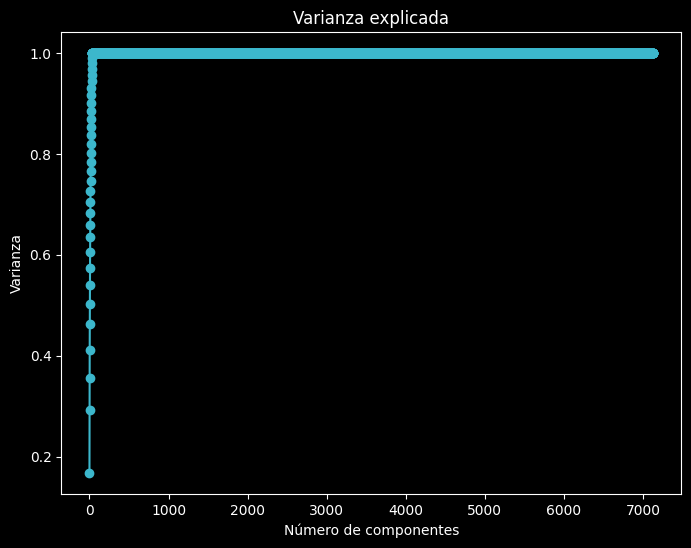

In [11]:
explained_var = np.cumsum(eigenvalues) / np.sum(eigenvalues) 
plt.figure(figsize=(8, 6))
plt.plot(explained_var, marker='o', color='#3CB7CC')
plt.title('Varianza explicada')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza')
plt.show()

In [14]:
explained_var[1]

np.complex128(0.2917614632826275+1.4244499110382475e-33j)

Text(0, 0.5, 'Varianza')

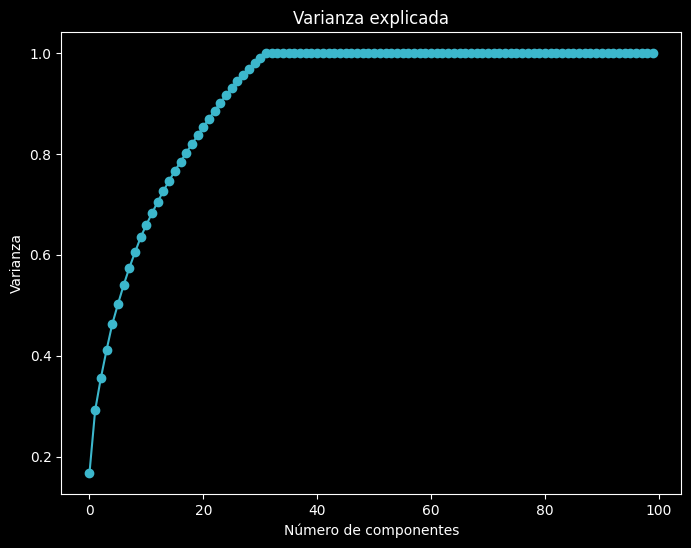

In [85]:
plt.figure(figsize=(8, 6))
plt.plot(explained_var[:100], marker='o', color='#3CB7CC')
plt.title('Varianza explicada')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza')

In [47]:
eigenvectors

array([[ 1.37501793e-02+0.j        ,  2.39168963e-03+0.j        ,
         7.46745283e-05+0.j        , ...,  6.40147686e-03+0.j        ,
         4.33732163e-02+0.00365363j,  4.33732163e-02-0.00365363j],
       [ 6.94542720e-03+0.j        , -2.88596130e-03+0.j        ,
        -6.68310517e-03+0.j        , ..., -1.60044192e-03+0.j        ,
        -7.17948446e-03+0.00634376j, -7.17948446e-03-0.00634376j],
       [-3.95292594e-04+0.j        , -2.96318854e-03+0.j        ,
         7.54372957e-03+0.j        , ...,  2.21851613e-03+0.j        ,
        -2.15905181e-02+0.00935642j, -2.15905181e-02-0.00935642j],
       ...,
       [-8.26146627e-03+0.j        ,  1.46444610e-02+0.j        ,
         1.28605987e-02+0.j        , ..., -2.43063073e-03+0.j        ,
        -4.91390988e-03+0.00103055j, -4.91390988e-03-0.00103055j],
       [-6.75645668e-04+0.j        , -2.64268099e-03+0.j        ,
        -1.59870840e-02+0.j        , ..., -4.65580581e-03+0.j        ,
        -1.21119831e-02+0.00042285j

In [46]:
type(eigenvectors)

numpy.ndarray

In [44]:
eigenvectors.dtype

dtype('complex128')

In [45]:
eigenvectors = float(eigenvectors)
eigenvectors

TypeError: only length-1 arrays can be converted to Python scalars

In [52]:
n_components = 2
u = eigenvectors[:,:n_components]
pca_component = pd.DataFrame(u,index = dataset.columns ,columns = ['PC1','PC2'])
pca_component.head()

,PC1,PC2
Gene Accession Number,,
AFFX-BioB-5_at,0.013750+0.000000j,0.002392+0.000000j
AFFX-BioB-M_at,0.006945+0.000000j,-0.002886+0.000000j
AFFX-BioB-3_at,-0.000395+0.000000j,-0.002963+0.000000j
AFFX-BioC-5_at,-0.007773+0.000000j,0.011487+0.000000j
AFFX-BioC-3_at,0.019386+0.000000j,0.006395+0.000000j


In [53]:
pca_dataset = standard_dataset @ pca_component
pca_dataset.head() 

,PC1,PC2
patient,,
1,-21.305998+ 0.000000j,-1.142763+ 0.000000j
2,5.047645+ 0.000000j,8.146729+ 0.000000j
3,-56.127051+ 0.000000j,0.218817+ 0.000000j
4,-15.788057+ 0.000000j,-13.230800+ 0.000000j
5,32.195913+ 0.000000j,32.604717+ 0.000000j


In [68]:
pca_dataset = standard_dataset @ pca_component
pca_dataset = pca_dataset.astype('float')
pca_dataset['cancer'] = full_dataset['cancer']
pca_dataset.head()

d:\papeles maestria\ejercicios_maestria_icd\.venv\Lib\site-packages\pandas\core\dtypes\astype.py:133: ComplexWarning: Casting complex values to real discards the imaginary part
  return arr.astype(dtype, copy=True)


,PC1,PC2,cancer
patient,,,
1,-21.305998,-1.142763,ALL
2,5.047645,8.146729,ALL
3,-56.127051,0.218817,ALL
4,-15.788057,-13.230800,ALL
5,32.195913,32.604717,ALL


Text(0.5, 1.0, '2 PCA')

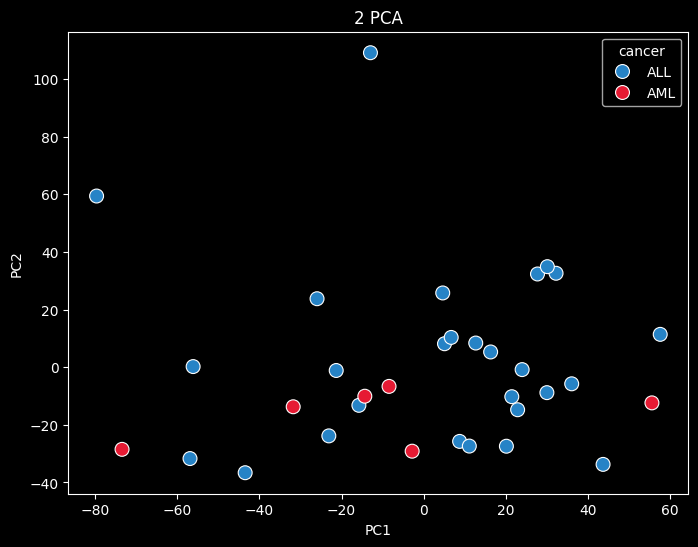

In [78]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='PC1', y='PC2', hue='cancer', data=pca_dataset, 
                palette={'AML': '#E61A33', 'ALL': '#2683C6'}, s=100)
plt.title('2 PCA')

# con la función pca

Text(0.5, 1.0, '2 PCA')

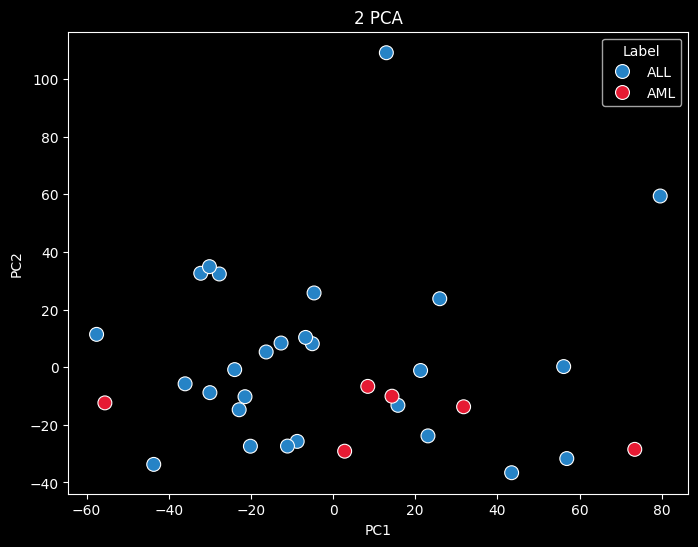

In [ ]:
dataset = pd.read_csv("datos\\data_set_ALL_AML_train.csv")
columnas = [str(i) for i in range(1,34)]
dataset = dataset[columnas]
X = dataset.T
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

labels = pd.read_csv("datos\\actual.csv")
y = labels['cancer'][:33] 

pca = PCA(n_components=2) 
principal_components = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(principal_components, columns=['PC1', 'PC2'])
pca_df['Label'] = y.values 

plt.figure(figsize=(8, 6))
sns.scatterplot(x='PC1', y='PC2', hue='Label', data=pca_df, 
                palette={'AML': '#E61A33', 'ALL': '#2683C6'}, s=100)
plt.title('2 PCA')
